In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("/content/Titanic-Dataset (1).csv")

print("Original Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

Original Dataset:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500  

In [ ]:
print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fa

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Value Percentage:
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [ ]:
# Fill numerical missing values with median
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

print("\nMissing Values After Treatment:")
print(df.isnull().sum())


Missing Values After Treatment:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [ ]:
print("\nDuplicate Rows Before:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate Rows After:", df.duplicated().sum())


Duplicate Rows Before: 0
Duplicate Rows After: 0


In [ ]:
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize Sex values if the column exists
if "Sex" in df.columns:
    df["Sex"] = df["Sex"].str.lower()

In [ ]:
if "Survived" in df.columns:
    df["Survived"] = pd.to_numeric(
        df["Survived"], errors="coerce"
    )

if "Pclass" in df.columns:
    df["Pclass"] = pd.to_numeric(
        df["Pclass"], errors="coerce"
    )

if "Age" in df.columns:
    df["Age"] = pd.to_numeric(
        df["Age"], errors="coerce"
    )

if "Fare" in df.columns:
    df["Fare"] = pd.to_numeric(
        df["Fare"], errors="coerce"
    )

print("\nData Types After Cleaning:")
print(df.dtypes)


Data Types After Cleaning:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nOutliers in {col}: {len(outliers)}")
    print(f"Lower Bound: {lower_bound}")
    print(f"Upper Bound: {upper_bound}")


Outliers in PassengerId: 0
Lower Bound: -444.0
Upper Bound: 1336.0

Outliers in Survived: 0
Lower Bound: -1.5
Upper Bound: 2.5

Outliers in Pclass: 0
Lower Bound: 0.5
Upper Bound: 4.5

Outliers in Age: 66
Lower Bound: 2.5
Upper Bound: 54.5

Outliers in SibSp: 46
Lower Bound: -1.5
Upper Bound: 2.5

Outliers in Parch: 213
Lower Bound: 0.0
Upper Bound: 0.0

Outliers in Fare: 116
Lower Bound: -26.724
Upper Bound: 65.6344


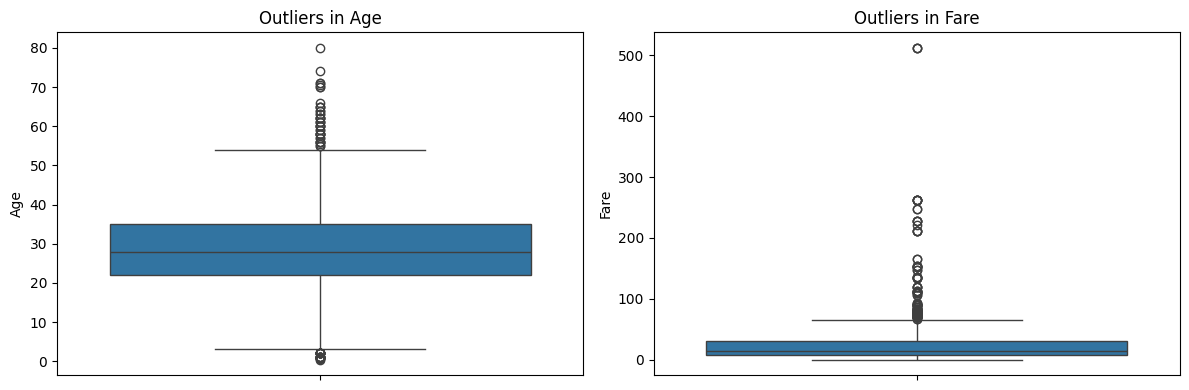

In [ ]:
plot_cols = [
    col for col in ["Age", "Fare"]
    if col in df.columns
]

if plot_cols:
    fig, axes = plt.subplots(
        1, len(plot_cols),
        figsize=(6 * len(plot_cols), 4)
    )

    if len(plot_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, plot_cols):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(f"Outliers in {col}")

    plt.tight_layout()
    plt.show()

In [ ]:
# Preserve Name as an identifier/text field rather
# than automatically encoding every passenger name.
categorical_cols = [
    col for col in ["Sex", "Embarked", "Pclass"]
    if col in df.columns
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("\nEncoded Dataset:")
print(df_encoded.head())


Encoded Dataset:
   PassengerId  Survived                                               Name  \
0            1         0                            Braund, Mr. Owen Harris   
1            2         1  Cumings, Mrs. John Bradley (Florence Briggs Th...   
2            3         1                             Heikkinen, Miss. Laina   
3            4         1       Futrelle, Mrs. Jacques Heath (Lily May Peel)   
4            5         0                           Allen, Mr. William Henry   

    Age  SibSp  Parch            Ticket     Fare    Cabin  Sex_male  \
0  22.0      1      0         A/5 21171   7.2500  B96 B98         1   
1  38.0      1      0          PC 17599  71.2833      C85         0   
2  26.0      0      0  STON/O2. 3101282   7.9250  B96 B98         0   
3  35.0      1      0            113803  53.1000     C123         0   
4  35.0      0      0            373450   8.0500  B96 B98         1   

   Embarked_Q  Embarked_S  Pclass_2  Pclass_3  
0           0           1       

In [ ]:
print("\nFinal Dataset Shape:", df_encoded.shape)

print("\nFinal Missing Values:")
print(df_encoded.isnull().sum())

print("\nFinal Duplicate Rows:",
      df_encoded.duplicated().sum())

print("\nFinal Dataset Summary:")
print(df_encoded.describe(include="all"))


Final Dataset Shape: (891, 14)

Final Missing Values:
PassengerId    0
Survived       0
Name           0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Sex_male       0
Embarked_Q     0
Embarked_S     0
Pclass_2       0
Pclass_3       0
dtype: int64

Final Duplicate Rows: 0

Final Dataset Summary:
        PassengerId    Survived                 Name         Age       SibSp  \
count    891.000000  891.000000                  891  891.000000  891.000000   
unique          NaN         NaN                  891         NaN         NaN   
top             NaN         NaN  Dooley, Mr. Patrick         NaN         NaN   
freq            NaN         NaN                    1         NaN         NaN   
mean     446.000000    0.383838                  NaN   29.361582    0.523008   
std      257.353842    0.486592                  NaN   13.019697    1.102743   
min        1.000000    0.000000                  NaN    0.420000    0.000000   
25%  